# PH 4050  Computational Electrodynamics

# Lab 3

2) Solving 1D Helmholtz equation Numerically

spacing h = 0.28559933214452665
points = [0.         0.28559933 0.57119866 0.856798   1.14239733 1.42799666
 1.71359599 1.99919533 2.28479466 2.57039399 2.85599332 3.14159265]


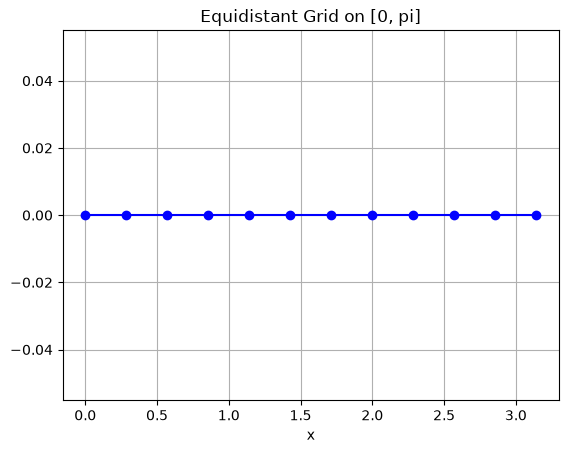

In [1]:
import numpy as np
import matplotlib.pyplot as plt

a = np.pi
N = 10

h = a / (N+1)
x = np.linspace(0, a, N + 2)

print("spacing h =", h)
print("points =", x)

plt.plot(x, np.zeros(N + 2), 'bo-')
plt.xlabel('x')
plt.title('Equidistant Grid on [0, pi]')
plt.grid()
plt.show()

3)

In [ ]:
f = np.sin(x)

a = np.pi
N = 10

h = a / (N+1)
x = np.linspace(0, a, N + 2)

grid_points = print("Grid points:", x[1:N + 1])
print("")

def second_derivative(f,h):
    d2f = np.zeros_like(f)
    for i in range(1, len(f) - 1):
        d2f[i] = (f[i + 1] - 2 * f[i] + f[i - 1]) / (h ** 2)
    return d2f[1:-1]

d2f = second_derivative(f, h)
print("Second derivative approximation:", d2f)

print("")

exact_d2f = -np.sin(x[1:N + 1])

print("Exact second derivative:", exact_d2f)




Grid points: [0.28559933 0.57119866 0.856798   1.14239733 1.42799666 1.71359599
 1.99919533 2.28479466 2.57039399 2.85599332]

Second derivative approximation: [-0.27982275 -0.53697592 -0.7506265  -0.90346579 -0.98311165 -0.98311165
 -0.90346579 -0.7506265  -0.53697592 -0.27982275]

Exact second derivative: [-0.28173256 -0.54064082 -0.75574957 -0.909632   -0.98982144 -0.98982144
 -0.909632   -0.75574957 -0.54064082 -0.28173256]


# 4) The sparse matrix

In [ ]:
import numpy as np
from scipy.sparse import csr_matrix, diags


main_diagonal = 2 * np.ones(N)
off_diagonal = -1 * np.ones(N - 1)

H = diags([off_diagonal, main_diagonal, off_diagonal],offsets=[-1, 0, 1],format="csr") / h**2

print("Sparse matrix representation of the second derivative operator:")
print(H.toarray())  

Sparse matrix representation of the second derivative operator:
[[ 24.51972644 -12.25986322   0.           0.           0.
    0.           0.           0.           0.           0.        ]
 [-12.25986322  24.51972644 -12.25986322   0.           0.
    0.           0.           0.           0.           0.        ]
 [  0.         -12.25986322  24.51972644 -12.25986322   0.
    0.           0.           0.           0.           0.        ]
 [  0.           0.         -12.25986322  24.51972644 -12.25986322
    0.           0.           0.           0.           0.        ]
 [  0.           0.           0.         -12.25986322  24.51972644
  -12.25986322   0.           0.           0.           0.        ]
 [  0.           0.           0.           0.         -12.25986322
   24.51972644 -12.25986322   0.           0.           0.        ]
 [  0.           0.           0.           0.           0.
  -12.25986322  24.51972644 -12.25986322   0.           0.        ]
 [  0.           0.    

5) The first two eigenvalues and then the eigenfrequencies

In [25]:
from scipy.sparse.linalg import eigsh

eigens, eigenvectors = eigsh(H, k=2, which="SM")

print("First two eigenvalues ", eigens)

eigen_freqs = np.sqrt(eigens)
print("First two eigenfrequencies ", eigen_freqs)




First two eigenvalues  [0.99322121 3.89241995]
First two eigenfrequencies  [0.99660484 1.97292168]


6) Different values of n (number of grid points). 

In [27]:
def sparse_second_derivative(f, h):
    N = len(f) - 2
    main_diagonal = 2 * np.ones(N)
    off_diagonal = -1 * np.ones(N - 1)
    H = diags([off_diagonal, main_diagonal, off_diagonal], offsets=[-1, 0, 1], format="csr") / h**2
    eigens, eigenvectors = eigsh(H, k=2, which="SM")
    return H.dot(f[1:N + 1]),eigens, eigenvectors

N_values = [10, 20, 50, 100]

for N in N_values:
    h = a / (N + 1)
    x = np.linspace(0, a, N + 2)
    f = np.sin(x)
    
    d2f_sparse, eigens, eigenvectors = sparse_second_derivative(f, h)
    
    print(f"\nFor N = {N}:")
    print("First two eigenvalues:", eigens)
    print("First two eigenfrequencies:", np.sqrt(eigens))


For N = 10:
First two eigenvalues: [0.99322121 3.89241995]
First two eigenfrequencies: [0.99660484 1.97292168]

For N = 20:
First two eigenvalues: [0.99813639 3.97024883]
First two eigenfrequencies: [0.99906776 1.99254832]

For N = 50:
First two eigenvalues: [0.99968383 3.99494317]
First two eigenfrequencies: [0.9998419  1.99873539]

For N = 100:
First two eigenvalues: [0.99991938 3.99871015]
First two eigenfrequencies: [0.99995969 1.99967751]


7) Zero-cell extrapolated values for the first two eigenfrequencies.  

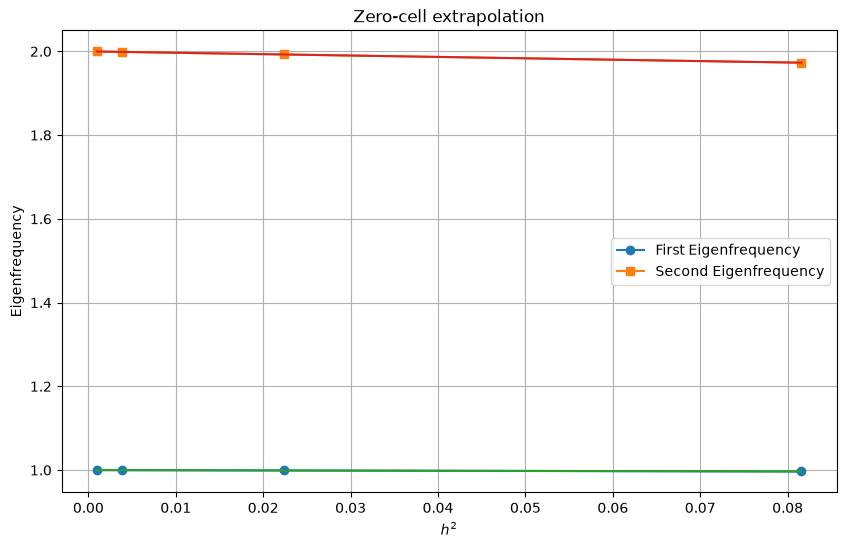

Extrapolated first eigenfrequency: 0.9999997277280949
Extrapolated second eigenfrequency: 1.9999913025952605


In [ ]:
import matplotlib.pyplot as plt

h_val=[]
eig_freqs_1=[]
eig_freqs_2=[]

for N in N_values:
    h = a / (N + 1)
    x = np.linspace(0, a, N + 2)
    f = np.sin(x)
    
    d2f_sparse, eigens, eigenvectors = sparse_second_derivative(f, h)
    
    h_val.append(h)
    eig_freqs_1.append(np.sqrt(eigens[0]))
    eig_freqs_2.append(np.sqrt(eigens[1]))


plt.figure(figsize=(10, 6))

slope_1, intercept_1 = np.polyfit(np.array(h_val)**2, np.array(eig_freqs_1), 1)
slope_2, intercept_2 = np.polyfit(np.array(h_val)**2, np.array(eig_freqs_2), 1)

plt.plot(np.array(h_val)**2, eig_freqs_1, 'o-', label='First Eigenfrequency')
plt.plot(np.array(h_val)**2, eig_freqs_2, 's-', label='Second Eigenfrequency')

plt.plot(np.array(h_val)**2, slope_1*np.array(h_val)**2 + intercept_1, '-')
plt.plot(np.array(h_val)**2, slope_2*np.array(h_val)**2 + intercept_2, '-')

plt.xlabel("$h^2$")
plt.ylabel("Eigenfrequency")
plt.title("Zero-cell extrapolation")
plt.legend()
plt.grid(True)
plt.show()




print("Extrapolated first eigenfrequency:", intercept_1)
print("Extrapolated second eigenfrequency:", intercept_2)

8) Accuracy of directly computed values and zero-cell extrapolated values. 

for zero extra =  0.9999997277280949 and 1.9999913025952605

for N = 100 direct computed eigen Frequencies are [0.99995969 ,1.99967751]

a clear differnce can be identified . 
mainly caused due to the error (big O) term that we neglect 
